In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

from keras.utils import load_img, img_to_array, set_random_seed
from keras.models import Sequential
from keras.layers import Input, Rescaling, Conv2D, Flatten, Dense, Dropout
from keras.callbacks import EarlyStopping


2026-10-28 11:48:59.660626: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-28 11:48:59.786172: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-28 11:48:59.786216: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-28 11:48:59.918696: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-28 11:49:02.015375: W tensorflow/compiler/tf

In [2]:
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
print("GPUs found:", gpus)

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2026-10-28 11:49:04.766085: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-28 11:49:05.187354: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-28 11:49:05.187616: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


In [3]:
# The UTKFace folder should be next to this notebook.
DATASET_DIR = r"UTKFace"

image_paths = []
for folder, subfolders, files in os.walk(DATASET_DIR):
    for filename in files:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(folder, filename))

print("Number of image files:", len(image_paths))


Number of image files: 23708


In [4]:
IMAGE_SIZE = 100
MAX_IMAGES = len(image_paths)

X = []  # images
y = []  # ages

for path in image_paths[:MAX_IMAGES]:
    filename = os.path.basename(path)
    try:
        age = int(filename.split("_")[0])
        image = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        image = img_to_array(image, dtype="uint8")
        X.append(image)
        y.append(age)
    except (ValueError, IndexError):
        pass

X = np.array(X, dtype="uint8")
y = np.array(y, dtype="float32")

print("Images shape:", X.shape)
print("Age labels shape:", y.shape)

Images shape: (23708, 100, 100, 3)
Age labels shape: (23708,)


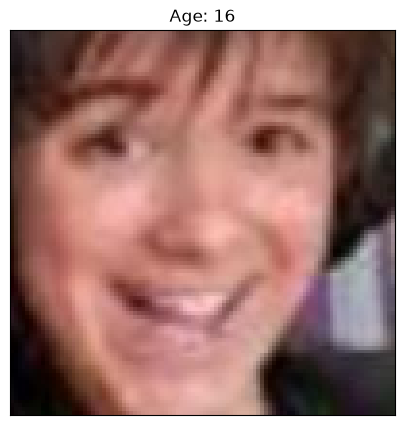

In [5]:
# Display some images and their ages

idk = 4327
plt.figure(figsize=(5, 5))
plt.imshow(X[idk].astype("uint8"))
plt.title(f"Age: {int(y[idk])}")
plt.xticks([])
plt.yticks([])
plt.grid(False)


plt.show()


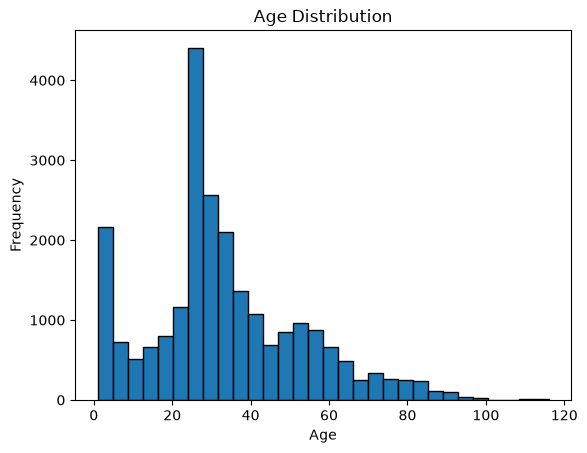

In [6]:
# Look at the distribution of ages
pd.Series(y, name="Age").plot(kind="hist", bins=30, edgecolor="black")
plt.xlabel("Age")
plt.title("Age Distribution")
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

## CNN Model

In [8]:
from tensorflow.keras.layers import MaxPooling2D

early_stop = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)
set_random_seed(42)

model = Sequential([
    Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),
    Rescaling(1./255),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),

    Dense(100, activation="relu"),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dropout(0.2),
    Dense(4, activation="relu"),

    Dense(1)
])

model.compile(optimizer="adam", loss="mean_squared_error", metrics=["mae"])

history = model.fit(X_train, y_train, validation_split=0.1, epochs=25, batch_size=32, callbacks=[early_stop])

2026-10-28 11:49:31.906882: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-28 11:49:31.907513: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-28 11:49:31.907734: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-28 11:49:33.004289: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-28 11:49:33.004484: I external/local_xla/xla/stream_executor

Epoch 1/25


I0000 00:00:1793177384.609272   71442 service.cc:145] XLA service 0x7e4240005a40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793177384.609342   71442 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce MX130, Compute Capability 5.0
2026-10-28 11:49:44.727836: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-28 11:49:45.441740: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


  1/534 ━━━━━━━━━━━━━━━━━━━━ 3:20:11 23s/step - loss: 1525.4941 - mae: 34.6666

I0000 00:00:1793177401.586071   71442 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_add_subtract_fusion_2', 4 bytes spill stores, 12 bytes spill loads

I0000 00:00:1793177401.599530   71442 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


533/534 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - loss: 567.9453 - mae: 18.4459

I0000 00:00:1793177455.787424   71441 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_add_subtract_fusion_2', 4 bytes spill stores, 12 bytes spill loads



534/534 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - loss: 567.9985 - mae: 18.4478

2026-10-28 11:50:56.268712: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 56910000 exceeds 10% of free system memory.
2026-10-28 11:50:56.764800: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 56910000 exceeds 10% of free system memory.


534/534 ━━━━━━━━━━━━━━━━━━━━ 82s 112ms/step - loss: 567.9985 - mae: 18.4478 - val_loss: 312.2052 - val_mae: 13.0420
Epoch 2/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 36s 67ms/step - loss: 367.7900 - mae: 14.4272 - val_loss: 202.7426 - val_mae: 10.7345
Epoch 3/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 35s 66ms/step - loss: 311.0804 - mae: 13.1111 - val_loss: 286.2945 - val_mae: 12.5580
Epoch 4/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 35s 66ms/step - loss: 265.5298 - mae: 12.0656 - val_loss: 220.1225 - val_mae: 10.4711
Epoch 5/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 36s 67ms/step - loss: 231.6678 - mae: 11.1906 - val_loss: 128.0876 - val_mae: 8.1609
Epoch 6/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 35s 66ms/step - loss: 211.2366 - mae: 10.5256 - val_loss: 131.3102 - val_mae: 8.0204
Epoch 7/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 35s 66ms/step - loss: 191.1989 - mae: 10.0599 - val_loss: 197.8759 - val_mae: 9.8861
Epoch 8/25
534/534 ━━━━━━━━━━━━━━━━━━━━ 34s 64ms/step - loss: 182.5208 - mae: 9.7278 - val_loss: 124.1846 - val_mae: 7.7274
Epoch 9

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │     1,280,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,147,793 (15.82 MB)

 Trainable params: 1,382,597 (5.27 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,765,196 (10.55 MB)

In [10]:
# History dataframe
history_df = pd.DataFrame(history.history)
history_df


,loss,mae,val_loss,val_mae
0,567.998474,18.447844,312.205231,13.042019
1,367.790039,14.427248,202.742584,10.734461
2,311.080353,13.111098,286.294464,12.558035
3,265.529846,12.065633,220.122498,10.471061
4,231.667816,11.190643,128.087555,8.160944
5,211.236603,10.525636,131.310181,8.020427
6,191.198898,10.059867,197.875946,9.886076
7,182.520813,9.727848,124.184593,7.727391
8,165.037231,9.332129,89.799301,6.863429
9,162.245911,9.147504,104.150742,7.282748


In [11]:
y_pred_test = model.predict(X_test, verbose=0).flatten()

mae = mean_absolute_error(y_test, y_pred_test)
print("MAE:", round(mae, 0), "years")

2026-10-28 11:57:31.376774: W external/local_tsl/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 142260000 exceeds 10% of free system memory.


MAE: 7.0 years


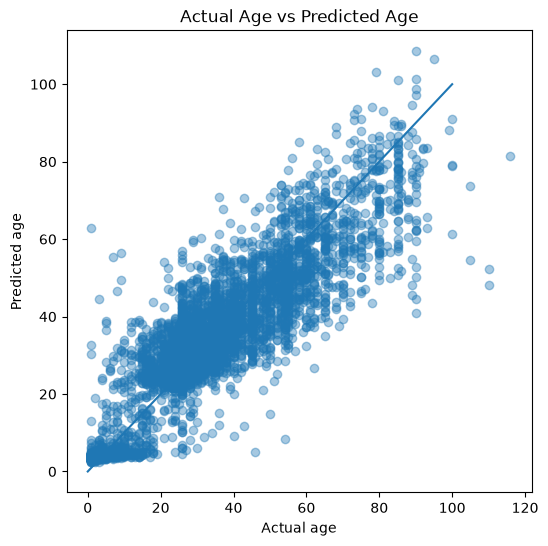

In [12]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_test, alpha=0.4)
plt.xlabel("Actual age")
plt.ylabel("Predicted age")
plt.title("Actual Age vs Predicted Age")

# Perfect predictions would fall on this line
plt.plot([0, 100], [0, 100])
plt.show()

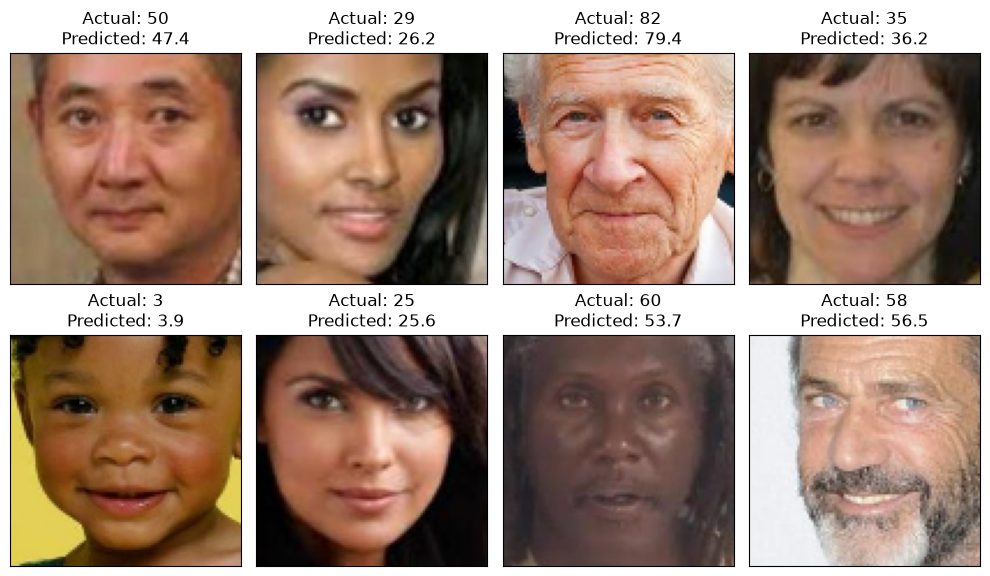

In [23]:
random_idx = np.random.choice(len(X_test), 8, replace=False)

plt.figure(figsize=(10, 6))

for plot_i, idx in enumerate(random_idx):
    plt.subplot(2, 4, plot_i + 1)
    plt.imshow(np.clip(X_test[idx], 0, 255).astype("uint8"))
    plt.title(f"Actual: {y_test[idx]:.0f}\nPredicted: {y_pred_test[idx]:.1f}")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

plt.tight_layout()
plt.show()

In [20]:
model.save("utkface_age_cnn.keras")